# Machine Learning Lab: Decision Tree and Random Forest Classification

## Wine Dataset

### Objectives

1. Implement a baseline Decision Tree and Random Forest classifier.
2. Experiment 1: vary `max_depth` for the Random Forest and compare Accuracy, Precision, and Recall using a graph.
3. Experiment 2: vary `n_estimators` and compare the same evaluation measures visually.

**Dataset:** Built-in scikit-learn Wine dataset using `sklearn.datasets.load_wine()`.

> Note: The built-in scikit-learn dataset is the Wine classification dataset. Its target represents three wine classes, rather than a numerical wine-quality score.


## 1. Import Required Libraries

The experiment uses scikit-learn for the dataset, classifiers, train-test split, and evaluation, with pandas and matplotlib for tabular results and graphs.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score


## 2. Load the Built-in Dataset

The Wine dataset is loaded directly from scikit-learn, so no external download is required. The predictor variables are chemical measurements and the target contains three wine classes.


In [2]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
display(df.head())
print("\nTarget classes:", wine.target_names)


Dataset shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Target classes: ['class_0' 'class_1' 'class_2']


## 3. Basic Data Check and Preparation

The dataset is numerical, so no categorical encoding is needed. A stratified 80:20 split is used to preserve the class proportions in the training and testing sets.


In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Number of features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Missing values: 0
Duplicate rows: 0
Number of features: 13
Training samples: 142
Testing samples: 36


## 4. Evaluation Measures

The classifiers are compared using Accuracy, Precision, and Recall. Weighted averages are used for Precision and Recall so that the class proportions are reflected in the reported scores.

- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** proportion of predicted instances that belong to the stated class.
- **Recall:** proportion of actual class instances that are correctly identified.


## 5. Baseline Decision Tree vs Random Forest

A single Decision Tree provides the baseline. It is then compared with a Random Forest containing 100 trees. Both models use the same training and testing data.


In [4]:
def evaluate(model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0)
    ]
    return scores, pred

dt = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

dt_scores, dt_pred = evaluate(dt)
rf_scores, rf_pred = evaluate(rf)

baseline = pd.DataFrame(
    [dt_scores, rf_scores],
    columns=["Accuracy", "Precision", "Recall"],
    index=["Decision Tree", "Random Forest"]
)

display(baseline.round(4))


,Accuracy,Precision,Recall
Decision Tree,0.9444,0.9514,0.9444
Random Forest,1.0000,1.0000,1.0000


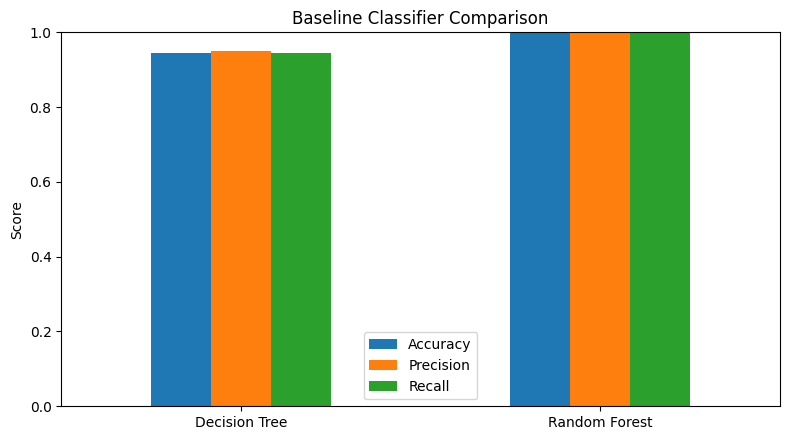

In [5]:
baseline.plot(kind="bar", ylim=(0, 1), figsize=(8, 4.5))
plt.title("Baseline Classifier Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 6. Experiment 1: Effect of max_depth

`max_depth` limits how deep the individual trees in the forest can grow. Several values are tested while keeping the forest size fixed at 100 trees.


In [6]:
depth_values = [2, 3, 4, 5, 6]
depth_results = []

for depth in depth_values:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )
    scores, _ = evaluate(model)
    depth_results.append([depth, *scores])

depth_results = pd.DataFrame(
    depth_results,
    columns=["max_depth", "Accuracy", "Precision", "Recall"]
)

display(depth_results.round(4))


,max_depth,Accuracy,Precision,Recall
0,2,0.9722,0.9744,0.9722
1,3,1.0000,1.0000,1.0000
2,4,1.0000,1.0000,1.0000
3,5,1.0000,1.0000,1.0000
4,6,1.0000,1.0000,1.0000


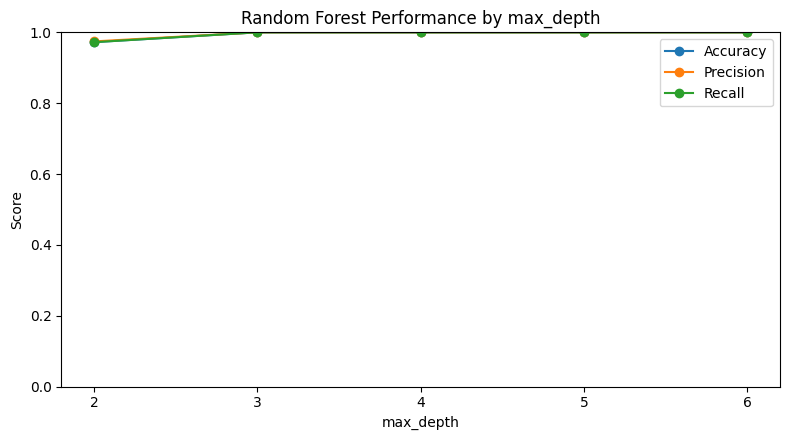

In [7]:
plt.figure(figsize=(8, 4.5))
for metric in ["Accuracy", "Precision", "Recall"]:
    plt.plot(depth_results["max_depth"], depth_results[metric],
             marker="o", label=metric)

plt.title("Random Forest Performance by max_depth")
plt.xlabel("max_depth")
plt.ylabel("Score")
plt.xticks(depth_values)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


### Observation

Very small depths restrict the trees and may underfit the data. Increasing the depth allows more detailed decision boundaries. The measured scores are used to identify the most suitable value among the tested settings.


## 7. Experiment 2: Effect of n_estimators

`n_estimators` specifies how many decision trees are combined in the Random Forest. Here, the maximum depth is fixed at 5 while the number of trees is changed.


In [8]:
estimator_values = [10, 50, 100, 200]
estimator_results = []

for n in estimator_values:
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    )
    scores, _ = evaluate(model)
    estimator_results.append([n, *scores])

estimator_results = pd.DataFrame(
    estimator_results,
    columns=["n_estimators", "Accuracy", "Precision", "Recall"]
)

display(estimator_results.round(4))


,n_estimators,Accuracy,Precision,Recall
0,10,1.0,1.0,1.0
1,50,1.0,1.0,1.0
2,100,1.0,1.0,1.0
3,200,1.0,1.0,1.0


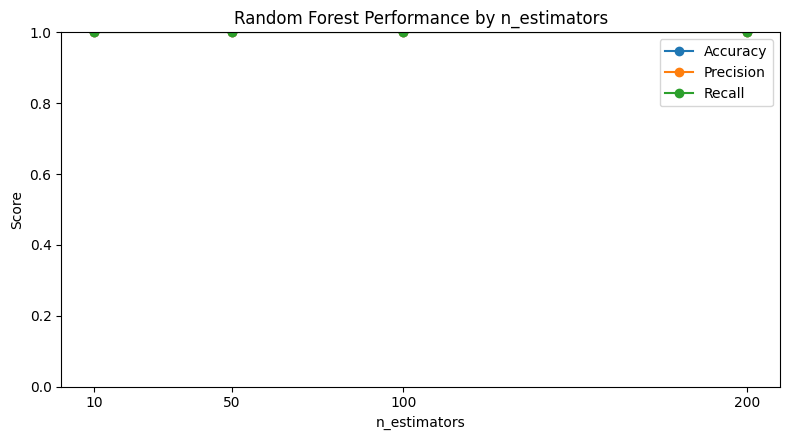

In [9]:
plt.figure(figsize=(8, 4.5))
for metric in ["Accuracy", "Precision", "Recall"]:
    plt.plot(estimator_results["n_estimators"], estimator_results[metric],
             marker="o", label=metric)

plt.title("Random Forest Performance by n_estimators")
plt.xlabel("n_estimators")
plt.ylabel("Score")
plt.xticks(estimator_values)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


### Observation

Adding more trees generally makes the ensemble more stable, but after a suitable number of trees the performance change becomes relatively small. The results provide a direct comparison of the tested ensemble sizes.


## 8. Key Findings

- The Random Forest provides a useful ensemble baseline against the single Decision Tree.
- `max_depth` affects the complexity of the trees and therefore the measured classification performance.
- `n_estimators` changes the size of the ensemble and can improve stability.
- Accuracy, Precision, and Recall give complementary views of classifier performance.
- The best parameter setting should be selected from the observed test results rather than assumed in advance.


## 9. Learning Outcomes

After completing the experiment, the following concepts were demonstrated:

- Training a Decision Tree classifier.
- Building a Random Forest classifier.
- Comparing two classification approaches using common evaluation measures.
- Studying the effect of tree depth on an ensemble model.
- Studying the effect of the number of trees.
- Presenting experimental results with tables and graphs.


## 10. Conclusion

Decision Tree and Random Forest classifiers were implemented using the built-in scikit-learn Wine dataset. The baseline models were compared first, followed by controlled experiments on `max_depth` and `n_estimators`. The results show how Random Forest parameters influence classification performance and illustrate the value of evaluating model settings empirically.
